# 01 — Environment Exploration

Inspect the autonomous-navigation task before training an agent. This notebook documents the **full simulator map** for the researcher; the agent itself receives only one-step local obstacle information.

## Environment at a glance

- 20×20 grid; fixed start at `(0, 0)`.
- Goal position is sampled from reachable free cells at the beginning of each episode and is fully visible.
- Fixed walls and **five moving patrol obstacles** are sensed only in the four cardinally adjacent cells (Manhattan distance ≤ 1).
- Four discrete actions: up, down, left, right.
- The patrol phase is included in the observation to expose the deterministic cycle clock.

Run this notebook before `02_dqn_training.ipynb`.


In [1]:
from pathlib import Path
import sys


def find_project_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").exists() and (candidate / "src" / "navigation_rl").is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not locate the project root. Start Jupyter from the project folder."
    )


PROJECT_ROOT = find_project_root()
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

print("Project root:", PROJECT_ROOT)


Project root: C:\Users\mhmd\Desktop\ML\1403\Notebooks\RL\03_01


In [2]:
import numpy as np
import matplotlib.pyplot as plt

from navigation_rl.environment import (
    NavigationGridWorld,
    OBSERVATION_DIM,
    SENSOR_RADIUS,
    ACTION_NAMES,
)

env = NavigationGridWorld()
observation, info = env.reset(seed=42)

print("Observation dimension:", OBSERVATION_DIM)
print("Observation dtype:", observation.dtype)
print("Agent:", info["agent_position"])
print("Visible goal:", info["goal_position"])
print("Moving obstacles:", info["moving_obstacle_positions"])
print("Sensor field: current cell + four cardinal neighbors (Manhattan distance <= 1)")


Observation dimension: 24
Observation dtype: float32
Agent: (0, 0)
Visible goal: (1, 12)
Moving obstacles: [(1, 8), (9, 4), (6, 13), (12, 13), (13, 1)]
Sensor field: current cell + four cardinal neighbors (Manhattan distance <= 1)


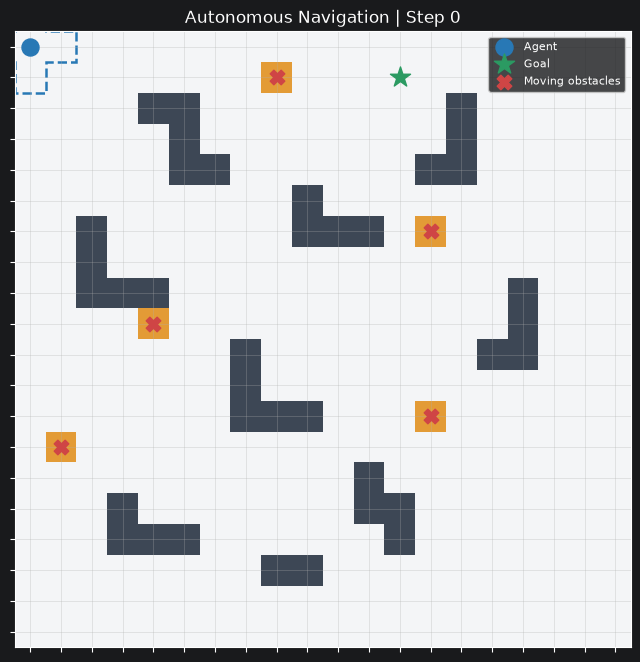

In [3]:
# The full map is shown for environment inspection only.
# The DQN receives only the one-step cardinal sensor encoding encoded in the observation vector.
fig, ax = plt.subplots(figsize=(8, 8))
env.render(ax=ax, show_sensor=True)
plt.show()


## Inspect the agent's local observation

The two 3×3 encodings below represent the center cell and its four cardinal neighbors. The diagonal entries are **not observable** and are kept at zero; this is a compact array representation, not a 3×3 field of view. Out-of-grid cardinal neighbors are reported as blocked cells.


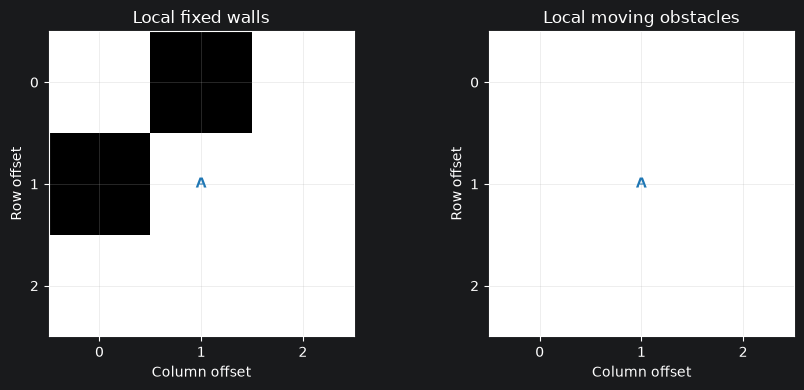

Patrol phase features (sin, cos): [0. 1.]


In [4]:
patch_size = 2 * SENSOR_RADIUS + 1
static_start = 4
moving_start = static_start + patch_size * patch_size
static_patch = observation[static_start:moving_start].reshape(patch_size, patch_size)
moving_patch = observation[moving_start:moving_start + patch_size * patch_size].reshape(patch_size, patch_size)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, matrix, title in [
    (axes[0], static_patch, "Local fixed walls"),
    (axes[1], moving_patch, "Local moving obstacles"),
]:
    ax.imshow(matrix, cmap="Greys", vmin=0, vmax=1)
    ax.set_title(title)
    ax.set_xticks(range(patch_size))
    ax.set_yticks(range(patch_size))
    ax.grid(alpha=0.3)
    ax.set_xlabel("Column offset")
    ax.set_ylabel("Row offset")
axes[0].text(SENSOR_RADIUS, SENSOR_RADIUS, "A", ha="center", va="center", color="tab:blue", weight="bold")
axes[1].text(SENSOR_RADIUS, SENSOR_RADIUS, "A", ha="center", va="center", color="tab:blue", weight="bold")
plt.tight_layout()
plt.show()

print("Patrol phase features (sin, cos):", observation[-2:].round(3))


## Check the transition interface

The environment follows a Gymnasium-style interface: `reset()` returns `(observation, info)` and `step()` returns `(observation, reward, terminated, truncated, info)`. The example below uses a fixed action sequence for inspection only; it is not a trained policy.

Initial position: (0, 0) Goal: (0, 6)
step=01 | action=DOWN  | agent=(1, 0) | reward= -0.515 | blocked=False
step=02 | action=DOWN  | agent=(2, 0) | reward= -0.510 | blocked=False
step=03 | action=RIGHT | agent=(2, 1) | reward=  0.485 | blocked=False
step=04 | action=RIGHT | agent=(2, 2) | reward=  0.480 | blocked=False
step=05 | action=DOWN  | agent=(3, 2) | reward= -0.515 | blocked=False
step=06 | action=RIGHT | agent=(3, 3) | reward=  0.480 | blocked=False


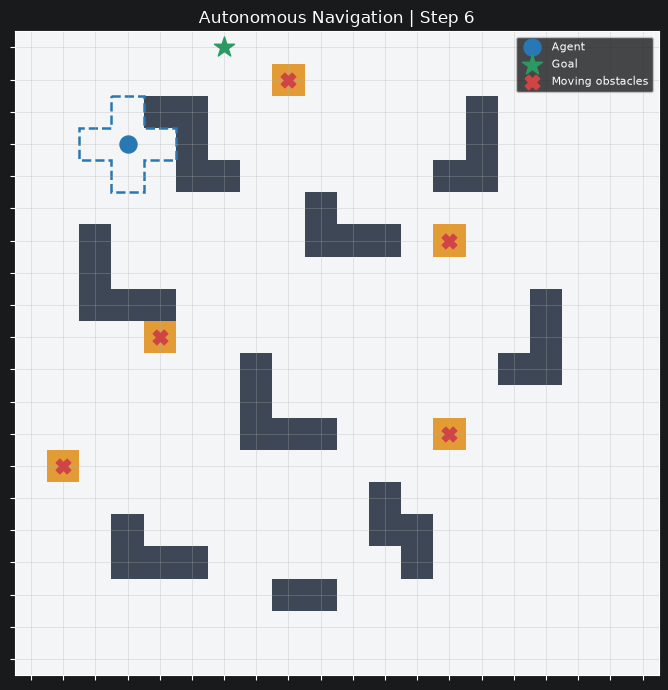

<Axes: title={'center': 'Autonomous Navigation | Step 6'}>

In [5]:
demo_env = NavigationGridWorld()
obs, demo_info = demo_env.reset(seed=123)
print("Initial position:", demo_env.agent_pos, "Goal:", demo_env.goal_pos)

for action in [1, 1, 3, 3, 1, 3]:
    obs, reward, terminated, truncated, info = demo_env.step(action)
    print(
        f"step={info['steps']:02d} | action={ACTION_NAMES[action]:5s} | "
        f"agent={info['agent_position']} | reward={reward:7.3f} | "
        f"blocked={info['blocked']}"
    )
    if terminated or truncated:
        break

demo_env.render(show_sensor=True)
